# Laboratorio 9: Series de tiempo y forecasting

CC3092 Deep Learning y Sistemas Inteligentes

Roberto Barreda 23354, Mia Fuentes 23775

Pronóstico day-ahead (H = 24 h) del consumo eléctrico horario de clientes de Portugal con el dataset ElectricityLoadDiagrams20112014.

## 0. Configuración

In [1]:
import os, time, random, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
fijar_semilla()

DATA_DIR, FIG_DIR, RES_DIR = "data", "figuras", "resultados"
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

# Periodos del problema
INICIO, FIN = pd.Timestamp("2012-01-01 00:00"), pd.Timestamp("2014-12-31 23:00")
INICIO_VAL, INICIO_TEST = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-10-01")
FIN_TRAIN, FIN_VAL = INICIO_VAL - pd.Timedelta("1h"), INICIO_TEST - pd.Timedelta("1h")
L, H = 168, 24

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

# Estilo de gráficas
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=COLORES), "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8c8b85", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
})

cuda NVIDIA GeForce RTX 4080 Laptop GPU


## 1. Datos

Se descarga el archivo de UCI una sola vez y se guarda en parquet para acelerar las siguientes cargas.

In [2]:
ruta_txt = os.path.join(DATA_DIR, "LD2011_2014.txt")
ruta_pq = os.path.join(DATA_DIR, "raw.parquet")
if os.path.exists(ruta_pq):
    raw = pd.read_parquet(ruta_pq)
else:
    if not os.path.exists(ruta_txt):
        url = ("https://archive.ics.uci.edu/static/public/321/"
               "electricityloaddiagrams20112014.zip")
        urllib.request.urlretrieve(url, os.path.join(DATA_DIR, "electricity.zip"))
        zipfile.ZipFile(os.path.join(DATA_DIR, "electricity.zip")).extract("LD2011_2014.txt", DATA_DIR)
    raw = pd.read_csv(ruta_txt, sep=";", decimal=",", index_col=0, parse_dates=True)
    raw.to_parquet(ruta_pq)
print(raw.shape)
raw.iloc[:3, :5]

(140256, 370)


,MT_001,MT_002,MT_003,MT_004,MT_005
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0


## 2. Exploración y preparación de la serie

### 2.1 Agregación horaria

Cada registro es la potencia media en kW de 15 minutos. La energía de una hora es la suma de los 4 registros por 0.25 h, que equivale a su promedio en kWh. En los días de cambio de horario de marzo los ceros aparecen en las marcas 01:00 a 01:45, por eso cada marca se asigna a la hora que la contiene (01:00 agrupa 01:00, 01:15, 01:30 y 01:45).

In [3]:
horario = raw.resample("h").mean().loc[INICIO:FIN]   # kWh por hora
# La marca 2012-01-01 00:00 pertenece a 2011 en varios clientes que inician a las 00:15, se usan las 3 marcas restantes
horario.loc[INICIO] = raw.loc[INICIO + pd.Timedelta("15min"):INICIO + pd.Timedelta("45min")].mean()
print(horario.shape, horario.index[0], horario.index[-1])

(26304, 370) 2012-01-01 00:00:00 2014-12-31 23:00:00


### 2.2 Filtro de clientes

Se conservan los clientes con consumo distinto de cero desde el 2012-01-01, que siguen activos al cierre de 2014 y sin rachas de ceros mayores a una semana dentro del periodo.

In [4]:
inicio_real = (raw > 0).idxmax()
fin_real = (raw[::-1] > 0).idxmax()

# Racha máxima de horas consecutivas en cero por cliente
cero = (horario == 0).to_numpy()
racha, actual = np.zeros(cero.shape[1], int), np.zeros(cero.shape[1], int)
for fila in cero:
    actual = np.where(fila, actual + 1, 0)
    racha = np.maximum(racha, actual)
racha = pd.Series(racha, index=horario.columns)

f_inicio = inicio_real <= INICIO + pd.Timedelta("15min")
f_fin = fin_real >= FIN
f_racha = racha <= 168
clientes = horario.columns[f_inicio & f_fin & f_racha]
print("Clientes originales:", horario.shape[1])
print("Inician después de 2012-01-01:", (~f_inicio).sum())
print("Dejan de consumir antes del cierre:", (f_inicio & ~f_fin).sum())
print("Con rachas de ceros > 1 semana:", (f_inicio & f_fin & ~f_racha).sum(), list(racha[f_inicio & f_fin & ~f_racha].items()))
print("Clientes finales:", len(clientes))
print("Observaciones horarias por serie:", horario.shape[0])
print("Observaciones del panel:", horario.shape[0] * len(clientes))

Clientes originales: 370
Inician después de 2012-01-01: 50
Dejan de consumir antes del cierre: 2
Con rachas de ceros > 1 semana: 1 [('MT_131', 1230)]
Clientes finales: 317
Observaciones horarias por serie: 26304
Observaciones del panel: 8338368


Pregunta: ¿Cuántos clientes quedan después del filtro del periodo 2012 a 2014? ¿Cuántas observaciones horarias tiene cada serie y cuántas tiene el panel completo?

Respuesta: Quedan 317 de 370 clientes. Se excluyen 50 que inician después del 2012-01-01, 2 que dejan de consumir antes del cierre de 2014 y MT_131, con 1,230 horas seguidas en cero. Cada serie tiene 26,304 observaciones horarias (1,096 días por 24 horas) y el panel 8,338,368.

### 2.3 Cambio de horario

En Portugal el horario de verano inicia el último domingo de marzo y termina el último domingo de octubre, ambos a la 01:00. La tabla muestra la suma del panel en las primeras horas de esos días.

In [5]:
def ultimo_domingo(anio, mes):
    d = pd.Timestamp(anio, mes, 1) + pd.offsets.MonthEnd(0)
    return d - pd.Timedelta(days=(d.dayofweek - 6) % 7)

horas_marzo = [ultimo_domingo(a, 3) + pd.Timedelta("1h") for a in (2012, 2013, 2014)]
horas_octubre = [ultimo_domingo(a, 10) + pd.Timedelta("1h") for a in (2012, 2013, 2014)]

panel = horario[clientes].copy()
def tabla_cambio(df):
    return pd.DataFrame({h.strftime("%Y-%m-%d"): df.loc[h - pd.Timedelta("1h"):h + pd.Timedelta("1h")].sum(axis=1).round(0).to_numpy()
                         for h in horas_marzo + horas_octubre}, index=["00:00", "01:00", "02:00"]).T
antes = tabla_cambio(panel)

# Marzo: la hora 01:00 no existe y viene en cero, se interpola con las horas vecinas
for h in horas_marzo:
    panel.loc[h] = (panel.loc[h - pd.Timedelta("1h")] + panel.loc[h + pd.Timedelta("1h")]) / 2
# Octubre: la hora 01:00 acumula dos horas, se divide entre 2
for h in horas_octubre:
    panel.loc[h] = panel.loc[h] / 2

pd.concat({"Antes": antes, "Después": tabla_cambio(panel)}, axis=1)

Antes                       Después                    
               00:00     01:00     02:00     00:00     01:00     02:00
2012-03-25  143614.0    4286.0  115338.0  143614.0  129476.0  115338.0
2013-03-31  135022.0    4330.0  112814.0  135022.0  123918.0  112814.0
2014-03-30  128289.0     419.0  103613.0  128289.0  115951.0  103613.0
2012-10-28  146414.0  238372.0  115509.0  146414.0  119186.0  115509.0
2013-10-27  140404.0  224145.0  107880.0  140404.0  112073.0  107880.0
2014-10-26  139542.0  233983.0  112249.0  139542.0  116992.0  112249.0

Pregunta: ¿Cómo tratarán los dos días de cambio de horario de cada año?

Respuesta: En marzo la hora 01:00 no existe y viene en cero, se reemplaza por el promedio de las 00:00 y las 02:00. En octubre la hora 01:00 acumula dos horas, se divide entre 2. Cada día conserva 24 horas sin huecos ni picos falsos.

### 2.4 Perfiles horarios, semanales y feriados

Para comparar clientes con escalas distintas, cada serie se divide entre su consumo medio de entrenamiento antes de promediar.

In [6]:
feriados_pt = holidays.Portugal(years=range(2012, 2016))
fechas_feriado = pd.DatetimeIndex(sorted(pd.Timestamp(d) for d in feriados_pt))
pd.DataFrame({"fecha": fechas_feriado, "feriado": [feriados_pt[d] for d in fechas_feriado]}).query("fecha <= @FIN")

,fecha,feriado
0,2012-01-01,Ano Novo
1,2012-04-06,Sexta-feira Santa
2,2012-04-08,Páscoa
3,2012-04-25,Dia da Liberdade
4,2012-05-01,Dia do Trabalhador
5,2012-06-07,Corpo de Deus
6,2012-06-10,"Dia de Portugal, de Camões e das Comunidades P..."
7,2012-08-15,Assunção de Nossa Senhora
8,2012-10-05,Implantação da República
9,2012-11-01,Dia de Todos os Santos


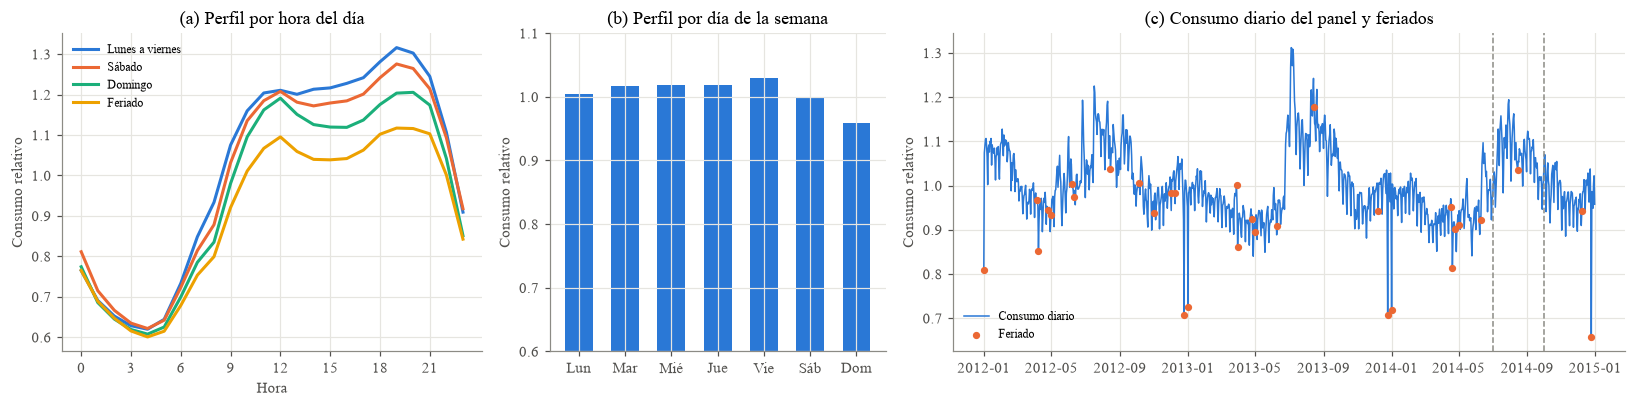

In [7]:
relativo = panel / panel.loc[:FIN_TRAIN].mean()
prom = relativo.mean(axis=1)
dia = prom.index.normalize()
es_feriado = dia.isin(fechas_feriado)
nombres_dia = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 0.8, 1.6]})
grupos = {"Lunes a viernes": (prom.index.dayofweek < 5) & ~es_feriado,
          "Sábado": (prom.index.dayofweek == 5) & ~es_feriado,
          "Domingo": (prom.index.dayofweek == 6) & ~es_feriado,
          "Feriado": es_feriado}
for nombre, m in grupos.items():
    ax[0].plot(range(24), prom[m].groupby(prom.index[m].hour).mean(), label=nombre)
ax[0].set(title="(a) Perfil por hora del día", xlabel="Hora", ylabel="Consumo relativo", xticks=range(0, 24, 3))
ax[0].legend(frameon=False, fontsize=8)

por_dia = prom[~es_feriado].groupby(prom.index[~es_feriado].dayofweek).mean()
ax[1].bar(nombres_dia, por_dia, color=COLORES[0], width=0.6)
ax[1].set(title="(b) Perfil por día de la semana", ylabel="Consumo relativo", ylim=(0.6, 1.1))

diario = prom.resample("D").mean()
ax[2].plot(diario.index, diario, lw=1, color=COLORES[0], label="Consumo diario")
fer = diario[diario.index.isin(fechas_feriado)]
ax[2].scatter(fer.index, fer, s=14, color=COLORES[1], zorder=3, label="Feriado")
for x in (INICIO_VAL, INICIO_TEST):
    ax[2].axvline(x, color="#8c8b85", ls="--", lw=1)
ax[2].set(title="(c) Consumo diario del panel y feriados", ylabel="Consumo relativo")
ax[2].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_perfiles.png"); plt.show()

Para Navidad y Año Nuevo se compara cada día con el promedio del mismo día de la semana en las tres semanas previas.

In [8]:
def razon_vs_semanas_previas(fecha, semanas=3):
    previas = [fecha - pd.Timedelta(weeks=k) for k in range(1, semanas + 1)]
    return diario.loc[fecha] / diario.loc[previas].mean()

tabla_fiestas = {}
for a in (2012, 2013, 2014):
    fechas = {"24 dic": f"{a}-12-24", "25 dic": f"{a}-12-25", "26 dic": f"{a}-12-26",
              "31 dic": f"{a}-12-31", "1 ene": f"{a + 1}-01-01"}
    tabla_fiestas[a] = {k: razon_vs_semanas_previas(pd.Timestamp(f)) if pd.Timestamp(f) <= FIN else np.nan
                        for k, f in fechas.items()}
tabla_fiestas = pd.DataFrame(tabla_fiestas)
tabla_fiestas.round(3)

,2012,2013,2014
24 dic,0.906,0.938,0.970
25 dic,0.688,0.702,0.667
26 dic,0.957,0.989,0.979
31 dic,0.963,0.976,0.976
1 ene,0.784,0.789,NaN


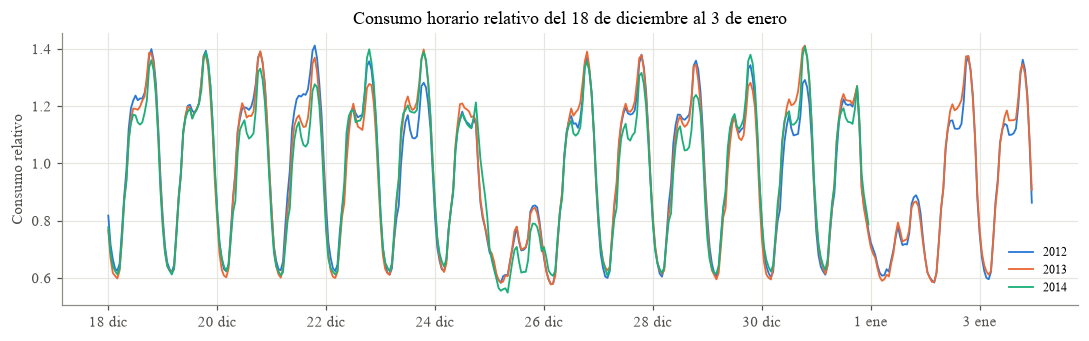

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, a in enumerate((2012, 2013, 2014)):
    tramo = prom.loc[f"{a}-12-18":f"{a + 1}-01-03"] if a < 2014 else prom.loc["2014-12-18":"2014-12-31"]
    ax.plot((tramo.index - pd.Timestamp(f"{a}-12-18")) / pd.Timedelta("1D"), tramo.to_numpy(), lw=1.2, label=str(a))
etiquetas = [pd.Timestamp("2000-12-18") + pd.Timedelta(days=d) for d in range(0, 17, 2)]
ax.set_xticks(range(0, 17, 2), [f"{d.day} {'dic' if d.month == 12 else 'ene'}" for d in etiquetas])
ax.set(title="Consumo horario relativo del 18 de diciembre al 3 de enero", ylabel="Consumo relativo")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_navidad.png"); plt.show()

Pregunta: ¿Cómo cambia el consumo en Navidad y Año Nuevo?

Respuesta: El 25 de diciembre el consumo cae a 67 % a 70 % del mismo día de la semana en las tres semanas previas y el 1 de enero a 78 % a 79 %. El 24 baja entre 3 % y 9 % y el 31 entre 2 % y 4 %, con la caída en la tarde y noche. El 26 vuelve al nivel normal. El 25 y el 1 de enero tienen un perfil de feriado con un pico de tarde menor, que es el caso que la covariable de feriado debe capturar.

### 2.5 Escalas entre clientes y normalización

min        4.33
50%      148.13
max    48818.08
dtype: float64
Razón máximo / mínimo: 11268


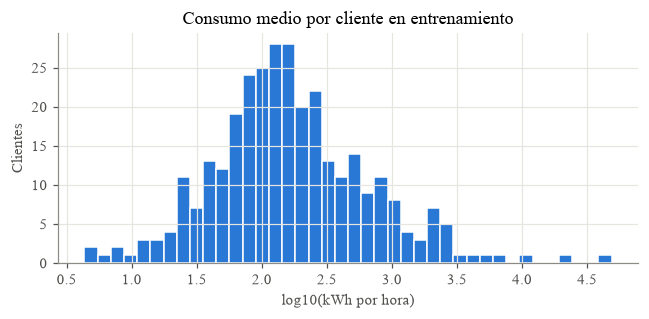

In [10]:
media_train = panel.loc[:FIN_TRAIN].mean()
print(media_train.describe()[["min", "50%", "max"]].round(2))
print("Razón máximo / mínimo:", round(media_train.max() / media_train.min()))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.log10(media_train), bins=40, color=COLORES[0], edgecolor="white", linewidth=1)
ax.set(title="Consumo medio por cliente en entrenamiento", xlabel="log10(kWh por hora)", ylabel="Clientes")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_escalas.png"); plt.show()

In [11]:
# z-score por serie con estadísticos solo de entrenamiento
def estadisticos(df):
    t = df.loc[:FIN_TRAIN]
    return t.mean(), t.std()

MU, SD = estadisticos(panel)
panel_norm = (panel - MU) / SD
print(panel_norm.loc[:FIN_TRAIN].mean().abs().max().round(6), panel_norm.loc[:FIN_TRAIN].std().mean().round(6))

0.0 1.0


Pregunta: ¿Qué tan distintas son las escalas entre clientes? Propongan y justifiquen una normalización.

Respuesta: El consumo medio en entrenamiento va de 4.33 kWh a 48,818 kWh por hora, con mediana de 148.13 kWh y una razón de 11,268 entre el mayor y el menor. Se usa z-score por serie con media y desviación de entrenamiento. Una normalización global dejaría a los clientes pequeños cerca de cero y la pérdida quedaría dominada por los grandes. La normalización por ventana (RevIN) queda como opción dentro de los modelos para cambios de nivel. Las métricas se calculan después de desnormalizar.

### 2.6 Covariables de calendario

Hora, día de la semana y mes se codifican con seno y coseno para conservar su carácter cíclico (la hora 23 queda junto a la 0) con dos columnas por variable. El feriado es una variable binaria tomada del calendario oficial de Portugal, que se conoce con anticipación.

In [12]:
def calendario(idx):
    hora, dia, mes = idx.hour.to_numpy(), idx.dayofweek.to_numpy(), idx.month.to_numpy() - 1
    return pd.DataFrame({
        "hora_sin": np.sin(2 * np.pi * hora / 24), "hora_cos": np.cos(2 * np.pi * hora / 24),
        "dia_sin": np.sin(2 * np.pi * dia / 7), "dia_cos": np.cos(2 * np.pi * dia / 7),
        "mes_sin": np.sin(2 * np.pi * mes / 12), "mes_cos": np.cos(2 * np.pi * mes / 12),
        "feriado": idx.normalize().isin(fechas_feriado).astype(float),
    }, index=idx)

CAL = calendario(panel.index)
CAL.loc["2014-12-24 22:00":"2014-12-25 02:00"].round(3)

,hora_sin,hora_cos,dia_sin,dia_cos,mes_sin,mes_cos,feriado
2014-12-24 22:00:00,-0.500,0.866,0.975,-0.223,-0.5,0.866,0.0
2014-12-24 23:00:00,-0.259,0.966,0.975,-0.223,-0.5,0.866,0.0
2014-12-25 00:00:00,0.000,1.000,0.434,-0.901,-0.5,0.866,1.0
2014-12-25 01:00:00,0.259,0.966,0.434,-0.901,-0.5,0.866,1.0
2014-12-25 02:00:00,0.500,0.866,0.434,-0.901,-0.5,0.866,1.0


Pregunta: ¿Cómo codifican las covariables de calendario conocidas a futuro?

Respuesta: Hora, día de la semana y mes con seno y coseno, 6 columnas que mantienen la continuidad cíclica en lugar de 43 columnas one-hot. El feriado es binario con el calendario oficial de Portugal del paquete holidays, que incluye la suspensión de 4 feriados entre 2013 y 2015. Todas se calculan con la marca de tiempo, por eso se conocen para las 24 horas futuras y entran al decoder en xf.

### 2.7 Dataset de ventanas deslizantes

Cada ventana tiene un origen t (primera hora a pronosticar). La entrada x usa las L horas anteriores al origen con el consumo normalizado y el calendario; xf trae el calendario de las H horas futuras para los modelos que lo usan en el decoder; y son las H horas siguientes. Una ventana pertenece a un bloque si todas sus horas objetivo caen en él. La entrada de validación y prueba puede tomar horas del bloque anterior porque ya son conocidas en el origen.

In [13]:
class VentanasDataset(Dataset):
    """x: (L, 1 + k) consumo normalizado y calendario pasado; xf: (H, k) calendario futuro; y: (H,)."""
    def __init__(self, valores, cal, primer_obj, ultimo_obj, L=L, H=H, stride=1):
        self.v = torch.as_tensor(np.asarray(valores), dtype=torch.float32)   # (n_series, T)
        self.c = torch.as_tensor(np.asarray(cal), dtype=torch.float32)       # (T, k)
        self.L, self.H = L, H
        self.origenes = np.arange(max(primer_obj, L), ultimo_obj - H + 2, stride)
        self.n_series = self.v.shape[0]

    def __len__(self):
        return self.n_series * len(self.origenes)

    def __getitem__(self, i):
        s, j = divmod(i, len(self.origenes))
        t = int(self.origenes[j])
        x = torch.cat([self.v[s, t - self.L:t, None], self.c[t - self.L:t]], dim=1)
        return x, self.c[t:t + self.H], self.v[s, t:t + self.H], s

    def lote(self, indices):
        """Versión vectorizada de __getitem__ para un arreglo de índices."""
        indices = torch.as_tensor(indices)
        s, j = indices // len(self.origenes), indices % len(self.origenes)
        t = torch.as_tensor(self.origenes)[j]
        pasado = t[:, None] + torch.arange(-self.L, 0)
        futuro = t[:, None] + torch.arange(self.H)
        x = torch.cat([self.v[s[:, None], pasado][..., None], self.c[pasado]], dim=2)
        return x, self.c[futuro], self.v[s[:, None], futuro], s


def iterar_lotes(ds, batch_size=512, barajar=False, max_lotes=None, device=DEVICE):
    orden = torch.randperm(len(ds)) if barajar else torch.arange(len(ds))
    for k, ini in enumerate(range(0, len(ds), batch_size)):
        if max_lotes is not None and k >= max_lotes:
            break
        yield [z.to(device) for z in ds.lote(orden[ini:ini + batch_size])]


POS_VAL, POS_TEST, T = panel.index.get_loc(INICIO_VAL), panel.index.get_loc(INICIO_TEST), len(panel)
V = panel_norm.to_numpy().T          # (n_series, T)
C = CAL.to_numpy()

ds_train = VentanasDataset(V, C, 0, POS_VAL - 1)
ds_val = VentanasDataset(V, C, POS_VAL, POS_TEST - 1)
ds_test = VentanasDataset(V, C, POS_TEST, T - 1)
# Orígenes diarios a las 00:00, los que usa el protocolo
ds_val_dia = VentanasDataset(V, C, POS_VAL, POS_TEST - 1, stride=24)
ds_test_dia = VentanasDataset(V, C, POS_TEST, T - 1, stride=24)

pd.DataFrame({
    "Ventanas por serie": [len(d.origenes) for d in (ds_train, ds_val, ds_test, ds_val_dia, ds_test_dia)],
    "Ventanas del panel": [len(d) for d in (ds_train, ds_val, ds_test, ds_val_dia, ds_test_dia)],
}, index=["Entrenamiento", "Validación", "Prueba", "Validación (00:00)", "Prueba (00:00)"])

,Ventanas por serie,Ventanas del panel
Entrenamiento,21697,6877949
Validación,2185,692645
Prueba,2185,692645
Validación (00:00),92,29164
Prueba (00:00),92,29164


In [14]:
x, xf, y, s = next(iter(DataLoader(ds_train, batch_size=64, shuffle=True)))
print("x", tuple(x.shape), "xf", tuple(xf.shape), "y", tuple(y.shape))
xb, xfb, yb, sb = ds_train.lote(torch.arange(64))
assert torch.equal(xb[10], ds_train[10][0]) and torch.equal(yb[10], ds_train[10][2])

x (64, 168, 8) xf (64, 24, 7) y (64, 24)


### 2.8 Auditoría de fugas

Cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico. Se revisan las cuatro fugas vistas en clase.

Fuga 1, split aleatorio de ventanas. Los bloques se definen por fecha de las horas objetivo y nunca se mezclan ventanas al azar entre bloques. Solo se barajan ventanas dentro de entrenamiento.

In [15]:
def rango_objetivo(ds):
    return panel.index[ds.origenes[0]], panel.index[ds.origenes[-1] + H - 1]

for nombre, d in [("train", ds_train), ("val", ds_val), ("test", ds_test)]:
    print(nombre, *rango_objetivo(d))
assert rango_objetivo(ds_train)[1] < rango_objetivo(ds_val)[0]
assert rango_objetivo(ds_val)[1] < rango_objetivo(ds_test)[0]

train 2012-01-08 00:00:00 2014-06-30 23:00:00
val 2014-07-01 00:00:00 2014-09-30 23:00:00
test 2014-10-01 00:00:00 2014-12-31 23:00:00


Fuga 2, escalar con toda la serie. MU y SD salen solo de entrenamiento. Si se alteran los datos de validación y prueba, los estadísticos no cambian.

In [16]:
alterado = panel.copy()
alterado.loc[INICIO_VAL:] *= 10
mu_alt, sd_alt = estadisticos(alterado)
assert np.allclose(mu_alt, MU) and np.allclose(sd_alt, SD)
print("Estadísticos idénticos con validación y prueba alteradas")

Estadísticos idénticos con validación y prueba alteradas


Fuga 3, early stopping con la prueba. La función de entrenamiento solo recibe los datasets de entrenamiento y validación. El bloque de prueba solo entra a backtest, que registra cada modelo y no permite evaluarlo dos veces (sección 4).

In [17]:
def mae_mase_val(modelo, ds=ds_val_dia):
    """MAE (kWh) y MASE sobre orígenes diarios de validación."""
    modelo.eval(); err, cli = [], []
    with torch.no_grad():
        for x, xf, y, s in iterar_lotes(ds, 4096):
            err.append(((modelo(x, xf) - y) * SD_T[s][:, None]).abs()); cli.append(s)
    err, cli = torch.cat(err), torch.cat(cli)
    mae_cli = torch.zeros(len(MU_T), device=DEVICE).index_add_(0, cli, err.mean(1)) / torch.bincount(cli, minlength=len(MU_T))
    return err.mean().item(), (mae_cli / ESCALA_T).mean().item()


def entrenar(modelo, ds_entr, ds_valid, epochs=20, lr=1e-3, batch_size=512, paciencia=3,
             max_lotes=None, perdida=nn.MSELoss()):
    """Entrena con early stopping sobre validación. No recibe datos de prueba."""
    modelo.to(DEVICE)
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    historial, mejor, mejor_estado, sin_mejora = [], np.inf, None, 0
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter(); modelo.train(); acum, n = 0.0, 0
        for x, xf, y, s in iterar_lotes(ds_entr, batch_size, barajar=True, max_lotes=max_lotes):
            opt.zero_grad()
            loss = perdida(modelo(x, xf), y)
            loss.backward(); opt.step()
            acum += loss.item() * len(y); n += len(y)
        modelo.eval(); va, nv = 0.0, 0
        with torch.no_grad():
            for x, xf, y, s in iterar_lotes(ds_valid, 4096):
                va += perdida(modelo(x, xf), y).item() * len(y); nv += len(y)
        mae, mase = mae_mase_val(modelo)
        historial.append({"epoch": ep, "loss_train": acum / n, "loss_val": va / nv, "MAE_val": mae,
                          "MASE_val": mase, "seg_epoch": time.perf_counter() - t0})
        if va / nv < mejor:
            mejor, sin_mejora = va / nv, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    hist = pd.DataFrame(historial)
    hist.attrs["memoria_pico_MB"] = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else 0
    hist.attrs["seg_total"] = hist.seg_epoch.sum()
    return hist


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters()), sum(p.numel() for p in modelo.parameters() if p.requires_grad)

Fuga 4, covariables mal alineadas. La entrada x termina en la hora anterior al origen, xf corresponde exactamente a las horas objetivo y alterar cualquier valor desde el origen no cambia x.

In [18]:
i = 5000
t = int(ds_train.origenes[i]); x, xf, y, s = ds_train[i]
print("Última hora de x:", panel.index[t - 1], "| primera hora de y:", panel.index[t])
assert torch.allclose(xf, torch.as_tensor(CAL.iloc[t:t + H].to_numpy(), dtype=torch.float32))
assert torch.allclose(x[:, 1:], torch.as_tensor(CAL.iloc[t - L:t].to_numpy(), dtype=torch.float32))

V_alt = V.copy(); V_alt[:, t:] = 999
x_alt = VentanasDataset(V_alt, C, 0, POS_VAL - 1)[i][0]
assert torch.equal(x, x_alt)

# El feriado del 25 de diciembre aparece en xf de la ventana con origen ese día
t_nav = panel.index.get_loc(pd.Timestamp("2014-12-25"))
j = np.where(ds_test_dia.origenes == t_nav)[0][0]
print("feriado en xf el 25-dic:", ds_test_dia[j][1][:, -1].unique().tolist(), "| feriado en x:", ds_test_dia[j][0][:, -1].max().item())

Última hora de x: 2012-08-03 07:00:00 | primera hora de y: 2012-08-03 08:00:00
feriado en xf el 25-dic: [1.0] | feriado en x: 0.0


## 3. Investigación

La investigación de herramientas (nn.LSTM, nn.GRU, nn.Conv1d, nn.TransformerEncoderLayer, NeuralForecast, StatsForecast y Chronos) y de los conceptos solicitados está en el informe PDF.

## 4. Protocolo de validación y métricas

backtest(modelo) se implementa una sola vez. En cada uno de los 92 orígenes de prueba el modelo recibe el panel en kWh hasta las 23:00 del día anterior y devuelve los 24 pasos siguientes. Con reentrenar=True llama a modelo.fit(historia) al inicio de cada mes con ventana expandible (3 orígenes). MASE usa como escala el MAE del seasonal naive de 24 h en entrenamiento de cada cliente.

In [19]:
ESCALA_MASE = panel.loc[:FIN_TRAIN].diff(24).abs().mean()
MU_T, SD_T, ESCALA_T = (torch.as_tensor(v.to_numpy(), dtype=torch.float32, device=DEVICE) for v in (MU, SD, ESCALA_MASE))
ORIGENES_TEST = pd.date_range(INICIO_TEST, FIN.normalize(), freq="D")
ORIGENES_VAL = pd.date_range(INICIO_VAL, FIN_VAL.normalize(), freq="D")
EVALUADOS = set()

def backtest(modelo, nombre, origenes=ORIGENES_TEST, datos=None, reentrenar=False):
    """modelo.predict(historia, origen) -> arreglo (n_clientes, H) en kWh."""
    if origenes is ORIGENES_TEST:
        assert nombre not in EVALUADOS, f"{nombre} ya se evaluó en prueba"
        EVALUADOS.add(nombre)
    datos = panel if datos is None else datos
    n, filas, t_fit, t0 = datos.shape[1], [], 0.0, time.perf_counter()
    for o in origenes:
        historia = datos.loc[:o - pd.Timedelta("1h")]
        if reentrenar and o.day == 1:
            tf = time.perf_counter(); modelo.fit(historia); t_fit += time.perf_counter() - tf
        y_hat = np.asarray(modelo.predict(historia, o), dtype=float)
        ds = pd.date_range(o, periods=H, freq="h")
        filas.append(pd.DataFrame({
            "unique_id": np.repeat(datos.columns, H), "ds": np.tile(ds, n), "origen": o,
            "h": np.tile(np.arange(1, H + 1), n), "y": datos.loc[ds].to_numpy().T.ravel(), "y_hat": y_hat.ravel()}))
    pred = pd.concat(filas, ignore_index=True)
    pred["modelo"] = nombre
    pred.attrs["seg_inferencia"] = time.perf_counter() - t0 - t_fit
    pred.attrs["seg_reentrenamiento"] = t_fit
    return pred

In [20]:
def metricas(pred, escala=None):
    """Métricas globales en kWh sobre todos los clientes y orígenes."""
    escala = ESCALA_MASE if escala is None else escala
    e = pred.y_hat - pred.y
    pos = pred.y > 0
    mae_cli = e.abs().groupby(pred.unique_id).mean()
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "WAPE": e.abs().sum() / pred.y.abs().sum(),
            "MAPE": (e[pos].abs() / pred.y[pos]).mean() * 100,
            "MASE": (mae_cli / escala[mae_cli.index]).mean()}


def metricas_por_cliente(pred):
    e = pred.y_hat - pred.y
    g = pd.DataFrame({"ae": e.abs(), "se": e ** 2, "ape": e.abs() / pred.y.where(pred.y > 0),
                      "y": pred.y, "unique_id": pred.unique_id}).groupby("unique_id")
    out = pd.DataFrame({"MAE": g.ae.mean(), "RMSE": np.sqrt(g.se.mean()), "MAPE": g.ape.mean() * 100,
                        "consumo_medio": g.y.mean()})
    out["MASE"] = out.MAE / ESCALA_MASE[out.index]
    return out


def error_por_paso(pred):
    return (pred.y_hat - pred.y).abs().groupby(pred.h).mean()


def error_por_hora(pred):
    return (pred.y_hat - pred.y).abs().groupby(pred.ds.dt.hour).mean()


def metricas_navidad(pred):
    return metricas(pred[(pred.ds >= "2014-12-22") & (pred.ds < "2014-12-29")])

Prueba del protocolo con implementaciones directas de naive y seasonal naive. En la entrega 2 los baselines oficiales se entrenan con StatsForecast.

In [21]:
class SeasonalNaive:
    """m = 1 equivale al naive."""
    def __init__(self, m):
        self.m = m
    def fit(self, historia):
        return self
    def predict(self, historia, origen):
        pasos = np.arange(H) % self.m - self.m
        return historia.to_numpy()[pasos].T

pred_ref = {nombre: backtest(SeasonalNaive(m), nombre, origenes=ORIGENES_VAL)
            for nombre, m in [("Naive", 1), ("SNaive24", 24), ("SNaive168", 168)]}
pd.DataFrame({k: metricas(v) for k, v in pred_ref.items()}).T.round(3)

,MAE,RMSE,WAPE,MAPE,MASE
Naive,322.627,2839.636,0.427,41.918,4.567
SNaive24,52.417,472.413,0.069,13.699,1.000
SNaive168,69.352,775.144,0.092,12.787,1.199


En validación el seasonal naive de 24 h es la referencia a superar (MASE de 1.00). El naive repite la última hora observada y su error crece con el paso del horizonte.

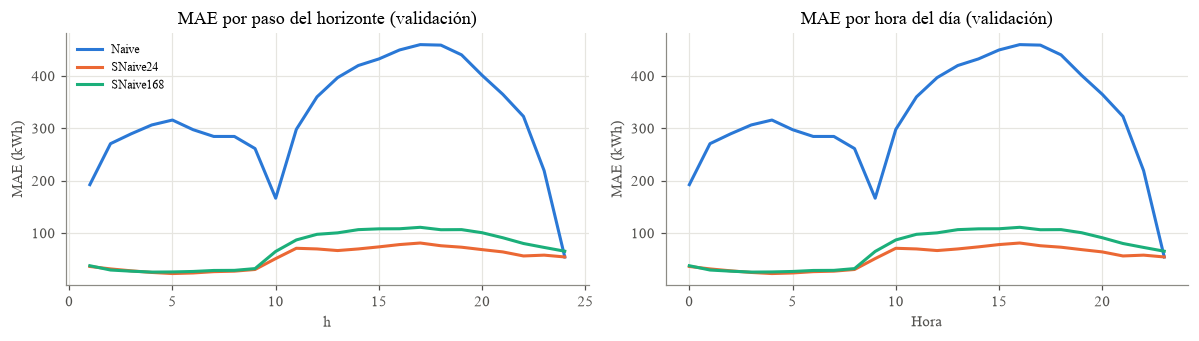

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for k, v in pred_ref.items():
    ax[0].plot(error_por_paso(v), label=k)
    ax[1].plot(error_por_hora(v), label=k)
ax[0].set(title="MAE por paso del horizonte (validación)", xlabel="h", ylabel="MAE (kWh)")
ax[1].set(title="MAE por hora del día (validación)", xlabel="Hora", ylabel="MAE (kWh)")
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [23]:
cli = metricas_por_cliente(pred_ref["SNaive24"])
print("Correlación de Spearman entre consumo medio y MAPE:", round(cli[["consumo_medio", "MAPE"]].corr("spearman").iloc[0, 1], 3))
p = pred_ref["SNaive24"]
ape = (p.y_hat - p.y).abs() / p.y.where(p.y > 0)
print("Horas con consumo cero en validación (MAPE indefinido):", int((p.y == 0).sum()))
print("MAPE en horas con y < 1 kWh:", round(ape[p.y < 1].mean() * 100, 1), "| resto:", round(ape[p.y >= 1].mean() * 100, 1))
cli.sort_values("MAPE", ascending=False).head(5).round(2)

Correlación de Spearman entre consumo medio y MAPE: -0.408
Horas con consumo cero en validación (MAPE indefinido): 3769
MAPE en horas con y < 1 kWh: 351.0 | resto: 13.4


,MAE,RMSE,MAPE,consumo_medio,MASE
unique_id,,,,,
MT_093,36.41,78.19,579.19,51.32,2.23
MT_090,58.12,94.85,193.16,130.80,1.05
MT_001,2.39,4.93,93.63,8.61,1.18
MT_366,9.55,14.23,84.84,12.12,1.22
MT_094,17.39,37.26,80.16,27.55,1.20


Pregunta: ¿Qué le pasa al MAPE con clientes de consumo cercano a cero?

Respuesta: En validación hay 3,769 horas con consumo cero donde el MAPE no está definido y se excluyen. En horas con consumo menor a 1 kWh el MAPE del seasonal naive llega a 351 % contra 13.4 % en el resto, y los clientes con mayor MAPE tienen consumo medio bajo (correlación de Spearman de -0.41). Un error de pocos kWh en un cliente pequeño pesa más que uno de cientos en un cliente grande, por eso la comparación se basa en WAPE y MASE.

Prueba de humo del ciclo de entrenamiento con una capa lineal sobre la ventana de consumo, para confirmar las formas de los tensores y el registro por epoch.

In [24]:
class LinealHumo(nn.Module):
    def __init__(self):
        super().__init__()
        self.capa = nn.Linear(L, H)
    def forward(self, x, xf):
        return self.capa(x[..., 0])

fijar_semilla()
humo = LinealHumo()
hist = entrenar(humo, ds_train, ds_val, epochs=2, max_lotes=300, batch_size=1024)
print(contar_parametros(humo), round(hist.attrs["memoria_pico_MB"], 1), "MB")
hist.round(4)

(4056, 4056) 71.8 MB


,epoch,loss_train,loss_val,MAE_val,MASE_val,seg_epoch
0,1,0.2099,0.1405,60.7233,1.0353,12.3834
1,2,0.1350,0.1273,56.5188,0.9607,11.0872
